<div style="background:linear-gradient(90deg,#0A6E68,#0FB9B1);padding:22px 28px;border-radius:10px;margin:18px 0 10px 0;"><h1 style="color:#ffffff;margin:0;font-weight:normal;">1. Understanding Data — raw REFIT, House 1</h1></div>

Before cleaning, I look at the raw files to see what is wrong with them. This notebook only **reads** the data, it never changes any file.

Questions I want to answer:
1. Do the timestamps parse, and are the rows in order?
2. Are there duplicate timestamps?
3. How regular is the sampling, and where are the gaps?
4. What does a missing reading look like (`NaN` or `0`)?
5. Are there impossible or extreme values?
6. Do Part 1 and Part 2 overlap?

<div style="background:linear-gradient(90deg,#0A6E68,#0FB9B1);padding:22px 28px;border-radius:10px;margin:18px 0 10px 0;"><h2 style="color:#ffffff;margin:0;font-weight:normal;">0. What the dataset documentation says</h2></div>

From `docs/Cleaned REFIT readme.txt`:

- 20 UK households (Houses 1–21, no House 14), Loughborough area, 2013–2015.
- Each house has **10 power sensors**: one on whole house (**Aggregate**) and 9 **Individual Appliance Monitors (IAMs)** → columns `Appliance1 … Appliance9`.
- Only **active power in watts (W)** is recorded.
- They "only recorded when there was a change in load", and the sensors are **not synchronised** (a value may be up to 6–8 s old).
- Each house's raw data is split into two files:
  - `_Part1` — sensors that were **unavailable were set to `0`**.
  - `_Part2` — unavailable sensors were set to **`NaN`**, "to distinguish from 0".
- The **raw** files have no corrections. The official **cleaned** files additionally: correct for daylight saving (DST), forward-fill NaN, replace appliance spikes > 4000 W with 0, move IAM sections to the right appliance column, and add an `Issues` flag (1 when the sum of the IAMs exceeds the aggregate).

**House 1 channels** (readme, "APPLIANCE LIST"): channel *N* is column `ApplianceN`.

| Column | Appliance |
|---|---|
| `Aggregate` | whole house |
| `Appliance1` | Fridge |
| `Appliance2` | Freezer (1) |
| `Appliance3` | Freezer (2) |
| `Appliance4` | **Washer Dryer** (not the washing machine) |
| `Appliance5` | **Washing Machine** (our target) |
| `Appliance6` | Dishwasher |
| `Appliance7` | Computer |
| `Appliance8` | Television Site |
| `Appliance9` | Electric Heater |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("dark")
pd.set_option("display.max_columns", 30)
pd.options.display.float_format = "{:,.2f}".format      # show 2 decimals and thousands commas

# House 1 channel names, from the readme appliance list
H1_NAMES = {
    "Aggregate": "Aggregate", "Appliance1": "Fridge", "Appliance2": "Freezer (1)",
    "Appliance3": "Freezer (2)", "Appliance4": "Washer Dryer", "Appliance5": "Washing Machine",
    "Appliance6": "Dishwasher", "Appliance7": "Computer", "Appliance8": "Television Site",
    "Appliance9": "Electric Heater",
}
CHANNELS = list(H1_NAMES)          # aggregate + 9 appliances
APPLIANCES = CHANNELS[1:]          # the 9 appliances only

<div style="background:linear-gradient(90deg,#0A6E68,#0FB9B1);padding:22px 28px;border-radius:10px;margin:18px 0 10px 0;"><h2 style="color:#ffffff;margin:0;font-weight:normal;">1. Load the two raw files</h2></div>

House 1 comes in two parts. We load them exactly as stored.

In [2]:
df_raw_h1_1 = pd.read_csv("../data/REFIT_RAW_081116/RAW_House1_Part1.csv")
df_raw_h1_2 = pd.read_csv("../data/REFIT_RAW_081116/RAW_House1_Part2.csv")
PARTS = {"Part1": df_raw_h1_1, "Part2": df_raw_h1_2}       # so we can loop over both

<div style="border-left:5px solid #0FB9B1;background:#E9FBFA;padding:10px 18px;border-radius:0 6px 6px 0;margin:14px 0 8px 0;"><h3 style="color:#12312F;margin:0;font-weight:normal;">1.1 First look: head() and tail()</h3></div>

Things to notice: the column names; that `Time` is a text timestamp and `Unix` is the same instant as seconds since 1970; that readings arrive every few seconds; and in Part 2 -> rows that are partly `NaN`.

In [3]:
df_raw_h1_1.head()

,Time,Unix,Aggregate,Appliance1,Appliance2,Appliance3,Appliance4,Appliance5,Appliance6,Appliance7,Appliance8,Appliance9
0,2013-10-09 14:06:17,1381327577,523,74,0,69,0,0,0,0,0,1
1,2013-10-09 14:06:31,1381327591,526,75,0,69,0,0,0,0,0,1
2,2013-10-09 14:06:46,1381327606,540,74,0,68,0,0,0,0,0,1
3,2013-10-09 14:07:01,1381327621,532,74,0,68,0,0,0,0,0,1
4,2013-10-09 14:07:15,1381327634,540,74,0,69,0,0,0,0,0,1


In [4]:
df_raw_h1_1.tail()

,Time,Unix,Aggregate,Appliance1,Appliance2,Appliance3,Appliance4,Appliance5,Appliance6,Appliance7,Appliance8,Appliance9
4377872,2014-10-01 01:26:38,1412126797,186,0,0,69,0,0,0,0,0,1
4377873,2014-10-01 01:26:51,1412126810,185,0,0,69,0,0,0,0,0,1
4377874,2014-10-01 01:26:52,1412126812,185,0,0,69,0,0,0,0,0,1
4377875,2014-10-01 01:27:07,1412126827,187,0,0,69,0,0,0,0,0,1
4377876,2014-10-01 01:27:07,1412126827,187,0,0,69,0,0,0,0,0,1


<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;"><span style="color:#0A6E68;">Part 1</span> runs from 2013-10-09 to 2014-10-01. The last two rows of <span style="color:#0A6E68;">tail()</span> have the same <span style="color:#0A6E68;">Time</span> <span style="color:#0A6E68;">and</span> the same values: a duplicated row.</div>

In [5]:
df_raw_h1_2.head()

,Time,Unix,Aggregate,Appliance1,Appliance2,Appliance3,Appliance4,Appliance5,Appliance6,Appliance7,Appliance8,Appliance9
0,2014-06-27 21:57:50,1403906269,322.00,0.00,0.00,72.00,0.00,0.00,0.00,0.00,NaN,NaN
1,2014-06-27 21:57:51,1403906271,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.00,1.00
2,2014-06-27 21:57:58,1403906278,329.00,NaN,0.00,NaN,NaN,0.00,0.00,0.00,30.00,NaN
3,2014-06-27 21:58:06,1403906286,322.00,0.00,0.00,71.00,NaN,NaN,NaN,0.00,30.00,NaN
4,2014-06-27 21:58:14,1403906293,320.00,0.00,0.00,NaN,NaN,0.00,0.00,0.00,30.00,NaN


In [6]:
df_raw_h1_2.tail()

,Time,Unix,Aggregate,Appliance1,Appliance2,Appliance3,Appliance4,Appliance5,Appliance6,Appliance7,Appliance8,Appliance9
4140881,2015-07-10 11:56:05,1436529364,187.00,0.00,45.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00
4140882,2015-07-10 11:56:12,1436529371,185.00,0.00,45.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00
4140883,2015-07-10 11:56:18,1436529377,181.00,0.00,45.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00
4140884,2015-07-10 11:56:25,1436529384,186.00,0.00,45.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00
4140885,2015-07-10 11:56:32,1436529392,182.00,0.00,45.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00


<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;"><span style="color:#0A6E68;">Part 2</span> runs from 2014-06-27 to 2015-07-10. Its first rows have <span style="color:#0A6E68;">NaN</span> in some appliances, so <span style="color:#0A6E68;">a Part 2 row is not a snapshot of all sensors at one instant</span>. It holds whichever sensors reported around that moment.</div>

<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;">Also note: <span style="color:#0A6E68;">Part 1 and Part 2 overlap for about three months</span> (section 5).</div>

<div style="border-left:5px solid #0FB9B1;background:#E9FBFA;padding:10px 18px;border-radius:0 6px 6px 0;margin:14px 0 8px 0;"><h3 style="color:#12312F;margin:0;font-weight:normal;">1.2 Data types</h3></div>

Two things to check: (a) `Time` should be a *date*, but it is stored as text (`object`); (b) Part 1 columns are integers but Part 2 columns are floats, because integers cannot hold `NaN`.

In [7]:
df_raw_h1_1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4377877 entries, 0 to 4377876
Data columns (total 12 columns):
 #   Column      Dtype 
---  ------      ----- 
 0   Time        object
 1   Unix        int64 
 2   Aggregate   int64 
 3   Appliance1  int64 
 4   Appliance2  int64 
 5   Appliance3  int64 
 6   Appliance4  int64 
 7   Appliance5  int64 
 8   Appliance6  int64 
 9   Appliance7  int64 
 10  Appliance8  int64 
 11  Appliance9  int64 
dtypes: int64(11), object(1)
memory usage: 400.8+ MB


In [8]:
df_raw_h1_2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4140886 entries, 0 to 4140885
Data columns (total 12 columns):
 #   Column      Dtype  
---  ------      -----  
 0   Time        object 
 1   Unix        int64  
 2   Aggregate   float64
 3   Appliance1  float64
 4   Appliance2  float64
 5   Appliance3  float64
 6   Appliance4  float64
 7   Appliance5  float64
 8   Appliance6  float64
 9   Appliance7  float64
 10  Appliance8  float64
 11  Appliance9  float64
dtypes: float64(10), int64(1), object(1)
memory usage: 379.1+ MB


<div style="background:linear-gradient(90deg,#0A6E68,#0FB9B1);padding:22px 28px;border-radius:10px;margin:18px 0 10px 0;"><h2 style="color:#ffffff;margin:0;font-weight:normal;">2. Timestamps</h2></div>

<div style="border-left:5px solid #0FB9B1;background:#E9FBFA;padding:10px 18px;border-radius:0 6px 6px 0;margin:14px 0 8px 0;"><h3 style="color:#12312F;margin:0;font-weight:normal;">2.1 Parse Time into real datetimes</h3></div>

`Time` is text, so I convert it into a new column `ts`. With `errors="coerce"`, a bad value becomes `NaT` instead of crashing, so we can count the bad ones.

In [9]:
for df in PARTS.values():
    df["ts"] = pd.to_datetime(df["Time"], errors="coerce")

pd.DataFrame({
    name: {
        "rows": len(df),
        "unparseable Time": int(df["ts"].isna().sum()),
        "first row": df["ts"].iloc[0],
        "last row": df["ts"].iloc[-1],
    }
    for name, df in PARTS.items()
})

,Part1,Part2
rows,4377877,4140886
unparseable Time,0,0
first row,2013-10-09 14:06:17,2014-06-27 21:57:50
last row,2014-10-01 01:27:07,2015-07-10 11:56:32


<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;">Every timestamp parses (0 unparseable).</div>

<div style="border-left:5px solid #0FB9B1;background:#E9FBFA;padding:10px 18px;border-radius:0 6px 6px 0;margin:14px 0 8px 0;"><h3 style="color:#12312F;margin:0;font-weight:normal;">2.2 Time versus Unix</h3></div>

Two columns describe the same instant. Do they agree?

In [10]:
for name, df in PARTS.items():
    diff = (df["ts"] - pd.to_datetime(df["Unix"], unit="s")).dt.total_seconds().round()
    print(name, "| Time minus Unix, in seconds -> number of rows:", diff.value_counts().to_dict())

Part1 | Time minus Unix, in seconds -> number of rows: {0.0: 2243876, 1.0: 2134001}
Part2 | Time minus Unix, in seconds -> number of rows: {0.0: 2122044, 1.0: 2018842}


<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;">The two columns differ by <span style="color:#0A6E68;">0 or 1 second</span> (rounding), never by hours. So <span style="color:#0A6E68;">Time</span> is simply <span style="color:#0A6E68;">Unix</span> printed as a calendar time.</div>

<div style="border-left:5px solid #0FB9B1;background:#E9FBFA;padding:10px 18px;border-radius:0 6px 6px 0;margin:14px 0 8px 0;"><h3 style="color:#12312F;margin:0;font-weight:normal;">2.3 Is the file in time order?</h3></div>

`diff()` gives the seconds between each row and the row before it. A **negative** step means the file goes back in time.

In [11]:
step = {name: df["ts"].diff().dt.total_seconds() for name, df in PARTS.items()}   # seconds since the previous row

for name, df in PARTS.items():
    print(name, "| sorted:", df["ts"].is_monotonic_increasing, "| steps back in time:", int((step[name] < 0).sum()))

# look at the rows around each backward step in Part 1
for idx in step["Part1"][step["Part1"] < 0].index:
    display(df_raw_h1_1.loc[idx - 2: idx + 2, ["Time", "Unix", "Aggregate"]])

Part1 | sorted: False | steps back in time: 2
Part2 | sorted: True | steps back in time: 0


,Time,Unix,Aggregate
249599,2013-10-27 01:59:47,1382839187,195
249600,2013-10-27 01:59:59,1382839198,197
249601,2013-10-27 01:00:01,1382835601,197
249602,2013-10-27 01:00:14,1382835614,196
249603,2013-10-27 01:00:16,1382835616,196


,Time,Unix,Aggregate
3790248,2014-08-15 02:00:35,1408068035,199
3790249,2014-08-15 02:00:36,1408068035,199
3790250,2014-08-15 02:00:35,1408068035,199
3790251,2014-08-15 02:00:52,1408068052,199
3790252,2014-08-15 02:00:52,1408068052,199


<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;">Part 2 is sorted. <span style="color:#0A6E68;">Part 1 goes back in time twice:</span></div>

<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;"><ol style="margin:6px 0 0 0;color:#12312F;"><li style="margin-bottom:4px;"><span style="color:#0A6E68;">27 Oct 2013:</span> <span style="color:#0A6E68;">01:59:59</span> is followed by <span style="color:#0A6E68;">01:00:01</span>. The UK clocks went back one hour that night (daylight saving), so the raw time is local clock time.</li>
<li style="margin-bottom:4px;"><span style="color:#0A6E68;">15 Aug 2014:</span> one row is 1 second earlier than its neighbour (the <span style="color:#0A6E68;">Unix</span> value is the same). Just jitter.</li></ol></div>

<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;"><span style="color:#0A6E68;">Fix later:</span> sort by time.</div>

<div style="border-left:5px solid #0FB9B1;background:#E9FBFA;padding:10px 18px;border-radius:0 6px 6px 0;margin:14px 0 8px 0;"><h3 style="color:#12312F;margin:0;font-weight:normal;">2.4 Duplicate timestamps</h3></div>

Two cases need different handling:
- **exact duplicates**: every column is the same, safe to drop.
- **same timestamp, different values**: the file disagrees with itself, so we need a rule.

In [12]:
df1 = df_raw_h1_1
same_ts = int(df1["ts"].duplicated().sum())      # rows whose timestamp already appeared
exact = int(df1.duplicated().sum())              # rows identical in every column to an earlier row

print(f"Part1 rows: {len(df1):,}")
print(f"rows repeating an earlier timestamp: {same_ts:,} ({100 * same_ts / len(df1):.1f}% of rows)")
print(f"   exact copies: {exact:,}")
print(f"   same timestamp but different values: {same_ts - exact:,}")
print(f"Part2 rows repeating an earlier timestamp: {int(df_raw_h1_2['ts'].duplicated().sum())}")

Part1 rows: 4,377,877
rows repeating an earlier timestamp: 645,514 (14.7% of rows)
   exact copies: 595,935
   same timestamp but different values: 49,579
Part2 rows repeating an earlier timestamp: 0


In [13]:
# an example where two rows share a timestamp but the Aggregate differs
dups = df1[df1["ts"].duplicated(keep=False)]
example = dups.groupby("ts")["Aggregate"].nunique().loc[lambda s: s > 1].index[0]
df1[df1["ts"] == example][["Time", "Aggregate", "Appliance1", "Appliance2", "Appliance5"]]

,Time,Aggregate,Appliance1,Appliance2,Appliance5
340,2013-10-09 14:41:00,1034,0,45,0
341,2013-10-09 14:41:00,1167,0,45,0


<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;">Part 1 has many duplicates, Part 2 has none. About 1 row in 7 repeats a timestamp. Most are exact copies (safe to drop), but some rows have <span style="color:#0A6E68;">different values at the same timestamp</span>. For those we need a stated rule (keep first, keep last, or average).</div>

<div style="border-left:5px solid #0FB9B1;background:#E9FBFA;padding:10px 18px;border-radius:0 6px 6px 0;margin:14px 0 8px 0;"><h3 style="color:#12312F;margin:0;font-weight:normal;">2.5 Sampling interval</h3></div>

If the data were regular, every step would be the same number of seconds. Here is the distribution of steps (anything above 20 s is shown as 20).

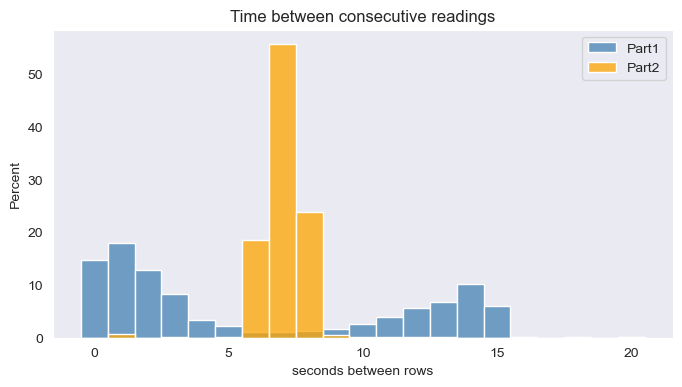

In [14]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.arange(-0.5, 21.5, 1)
sns.histplot(step["Part1"].dropna().clip(0, 20), bins=bins, stat="percent", color="steelblue", label="Part1", ax=ax)
sns.histplot(step["Part2"].dropna().clip(0, 20), bins=bins, stat="percent", color="orange", label="Part2", ax=ax)
ax.set(xlabel="seconds between rows", title="Time between consecutive readings")
ax.legend()
plt.show()

<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;"><ul style="margin:6px 0 0 0;color:#12312F;"><li style="margin-bottom:4px;"><span style="color:#0A6E68;">Part 2</span> is almost regular: most steps are 6, 7 or 8 seconds.</li>
<li style="margin-bottom:4px;"><span style="color:#0A6E68;">Part 1</span> is irregular: many 0–2 s steps (the duplicates) and another group around 12–15 s.</li></ul></div>

<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;">So neither file is on a regular grid. <span style="color:#0A6E68;">We must resample to 1 minute.</span></div>

<div style="border-left:5px solid #0FB9B1;background:#E9FBFA;padding:10px 18px;border-radius:0 6px 6px 0;margin:14px 0 8px 0;"><h3 style="color:#12312F;margin:0;font-weight:normal;">2.6 Gaps</h3></div>

A gap is a long step between two rows. First the counts, then every gap longer than 1 hour.

In [15]:
limits = [60, 300, 3600, 86400]
pd.DataFrame({name: {f"gaps > {b} s": int((s > b).sum()) for b in limits} for name, s in step.items()})

,Part1,Part2
gaps > 60 s,780,3603
gaps > 300 s,380,72
gaps > 3600 s,14,19
gaps > 86400 s,3,10


In [16]:
def long_gaps(df, min_seconds=3600):
    s = df["ts"].diff().dt.total_seconds()
    idx = s[s > min_seconds].index
    return pd.DataFrame({"gap_start": df["ts"].shift(1)[idx].values, "gap_end": df["ts"][idx].values,
                         "hours": (s[idx] / 3600).values, "days": (s[idx] / 86400).values})

print("Part1 gaps longer than 1 hour")
display(long_gaps(df_raw_h1_1))
print("Part2 gaps longer than 1 hour")
display(long_gaps(df_raw_h1_2))

Part1 gaps longer than 1 hour


,gap_start,gap_end,hours,days
0,2013-10-09 20:11:07,2013-10-09 21:23:50,1.21,0.05
1,2013-11-07 10:03:19,2013-11-08 11:42:14,25.65,1.07
2,2013-12-16 10:01:20,2013-12-16 11:06:09,1.08,0.05
3,2013-12-18 18:18:03,2013-12-18 19:40:35,1.38,0.06
4,2014-01-24 01:56:26,2014-03-06 16:23:19,998.45,41.60
5,2014-03-30 00:59:58,2014-03-30 02:00:02,1.00,0.04
6,2014-07-07 03:46:51,2014-07-07 09:32:50,5.77,0.24
7,2014-07-14 00:39:37,2014-07-14 01:53:57,1.24,0.05
8,2014-07-21 11:01:35,2014-07-21 13:08:18,2.11,0.09
9,2014-07-30 14:15:20,2014-07-30 15:15:23,1.00,0.04


Part2 gaps longer than 1 hour


,gap_start,gap_end,hours,days
0,2014-07-01 08:08:43,2014-07-01 18:02:13,9.89,0.41
1,2014-07-07 03:47:22,2014-07-07 14:44:20,10.95,0.46
2,2014-08-17 22:30:52,2014-08-18 00:03:43,1.55,0.06
3,2014-08-19 13:36:14,2014-08-19 14:43:33,1.12,0.05
4,2014-08-19 14:52:50,2014-08-19 16:11:41,1.31,0.05
5,2014-08-28 04:23:05,2014-09-01 16:55:25,108.54,4.52
6,2014-10-27 00:05:01,2014-10-28 13:46:50,37.70,1.57
7,2014-11-10 00:17:12,2014-11-10 13:15:54,12.98,0.54
8,2014-12-18 10:28:52,2014-12-19 10:37:47,24.15,1.01
9,2015-01-29 15:19:12,2015-01-29 17:16:45,1.96,0.08


<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;"><ul style="margin:6px 0 0 0;color:#12312F;"><li style="margin-bottom:4px;">Most gaps are short (a few minutes). A few are long: the longest in Part 1 is about <span style="color:#0A6E68;">41.6 days</span> (Jan–Mar 2014, the readme's "February 2014" outage). In Part 2 it is about 8.6 days.</li>
<li style="margin-bottom:4px;">One gap of exactly 1 hour (ending <span style="color:#0A6E68;">2014-03-30 02:00:02</span>) is just the clocks changing, not an outage.</li></ul></div>

<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;"><span style="color:#0A6E68;">Fix later:</span> fill short gaps only. Flag long ones, do not fill them.</div>

<div style="background:linear-gradient(90deg,#0A6E68,#0FB9B1);padding:22px 28px;border-radius:10px;margin:18px 0 10px 0;"><h2 style="color:#ffffff;margin:0;font-weight:normal;">3. Missing readings: what do 0 and NaN mean?</h2></div>

Part 1 uses `0` for "sensor not available", so a `0` there can mean "off" or "missing". Part 2 uses `NaN`. Here is the share of `NaN` and the share of exact zeros for each channel.

In [17]:
na_pct = pd.DataFrame({name: df[CHANNELS].isna().mean() * 100 for name, df in PARTS.items()}).rename(index=H1_NAMES)
zero_pct = pd.DataFrame({name: (df[CHANNELS] == 0).sum() / df[CHANNELS].notna().sum() * 100
                         for name, df in PARTS.items()}).rename(index=H1_NAMES)

print("% of rows that are NaN"); display(na_pct)
print("% of existing readings that are exactly 0"); display(zero_pct)

% of rows that are NaN


,Part1,Part2
Aggregate,0.00,4.56
Fridge,0.00,10.57
Freezer (1),0.00,11.10
Freezer (2),0.00,7.53
Washer Dryer,0.00,12.34
Washing Machine,0.00,12.01
Dishwasher,0.00,8.27
Computer,0.00,5.62
Television Site,0.00,9.44
Electric Heater,0.00,46.17


% of existing readings that are exactly 0


,Part1,Part2
Aggregate,0.00,0.00
Fridge,75.97,76.13
Freezer (1),63.58,65.27
Freezer (2),59.95,58.58
Washer Dryer,99.27,99.87
Washing Machine,97.87,97.68
Dishwasher,99.08,99.07
Computer,90.70,87.70
Television Site,81.04,81.10
Electric Heater,0.02,0.03


<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;"><ul style="margin:6px 0 0 0;color:#12312F;"><li style="margin-bottom:4px;"><span style="color:#0A6E68;">Part 1 has no NaN</span> (it used <span style="color:#0A6E68;">0</span> instead), so <span style="color:#0A6E68;">isna()</span> tells us nothing about its missing data.</li>
<li style="margin-bottom:4px;"><span style="color:#0A6E68;">Part 2 has a lot of NaN</span>: from about 4.6% of rows for <span style="color:#0A6E68;">Aggregate</span> to about 46% for the <span style="color:#0A6E68;">Electric Heater</span>.</li>
<li style="margin-bottom:4px;">The washing machine is <span style="color:#0A6E68;">0</span> in about 98% of readings. It is off most of the time.</li></ul></div>

Is a `NaN` a **short hole** (a sensor just did not report in that row) or a **real outage**? I measure how many rows in a row are `NaN`.

In [18]:
def nan_runs(s):
    # length (in rows) of every stretch of consecutive NaN
    isna = s.isna()
    run_id = (isna != isna.shift()).cumsum()           # new id each time NaN/not-NaN changes
    runs = isna.groupby(run_id).agg(["first", "size"])
    return runs.loc[runs["first"], "size"]

rows = {}
for c in ["Aggregate", "Appliance5", "Appliance9"]:
    r = nan_runs(df_raw_h1_2[c])
    rows[H1_NAMES[c]] = {"NaN stretches": len(r), "typical length (rows)": r.median(), "longest (rows)": r.max()}
pd.DataFrame(rows).T

,NaN stretches,typical length (rows),longest (rows)
Aggregate,"171,039.00",1.00,22.00
Washing Machine,"299,204.00",1.00,"1,073.00"
Electric Heater,"129,304.00",1.00,"128,592.00"


<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;"><ul style="margin:6px 0 0 0;color:#12312F;"><li style="margin-bottom:4px;">The typical <span style="color:#0A6E68;">NaN</span> stretch is <span style="color:#0A6E68;">1 row</span>. That is just staggered polling, not an outage.</li>
<li style="margin-bottom:4px;">A few stretches are very long, for example the Electric Heater has one of about 128,000 rows (about 10 days at 7 s per row).</li></ul></div>

<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;">So a <span style="color:#0A6E68;">NaN</span> is a mix of short holes and real outages. <span style="color:#0A6E68;">Fix later:</span> fill the short ones, flag the long ones.</div>

<div style="background:linear-gradient(90deg,#0A6E68,#0FB9B1);padding:22px 28px;border-radius:10px;margin:18px 0 10px 0;"><h2 style="color:#ffffff;margin:0;font-weight:normal;">4. Extreme and impossible values</h2></div>

<div style="border-left:5px solid #0FB9B1;background:#E9FBFA;padding:10px 18px;border-radius:0 6px 6px 0;margin:14px 0 8px 0;"><h3 style="color:#12312F;margin:0;font-weight:normal;">4.1 Summary statistics</h3></div>

In [19]:
print("Part1"); display(df_raw_h1_1[CHANNELS].describe().T.rename(index=H1_NAMES)[["mean", "50%", "max"]])
print("Part2"); display(df_raw_h1_2[CHANNELS].describe().T.rename(index=H1_NAMES)[["mean", "50%", "max"]])

Part1


,mean,50%,max
Aggregate,484.65,240.00,"24,000.00"
Fridge,19.60,0.00,"69,629.00"
Freezer (1),17.50,0.00,"98,301.00"
Freezer (2),29.16,0.00,"32,751.00"
Washer Dryer,8.19,0.00,"98,301.00"
Washing Machine,9.70,0.00,"32,767.00"
Dishwasher,10.85,0.00,"14,336.00"
Computer,1.93,0.00,"98,299.00"
Television Site,6.22,0.00,"65,549.00"
Electric Heater,79.13,1.00,"65,535.00"


Part2


,mean,50%,max
Aggregate,446.46,234.00,"29,159.00"
Fridge,18.84,0.00,"76,677.00"
Freezer (1),16.87,0.00,"66,685.00"
Freezer (2),30.14,0.00,"73,725.00"
Washer Dryer,1.73,0.00,"98,301.00"
Washing Machine,12.19,0.00,"73,725.00"
Dishwasher,11.33,0.00,"37,610.00"
Computer,3.97,0.00,"73,725.00"
Television Site,6.58,0.00,"98,301.00"
Electric Heater,73.77,1.00,"32,737.00"


<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;">The medians are small (appliances are mostly off), but some <span style="color:#0A6E68;">maximums are huge</span>: tens of thousands of watts, for a fridge or a computer. No negative values anywhere.</div>

<div style="border-left:5px solid #0FB9B1;background:#E9FBFA;padding:10px 18px;border-radius:0 6px 6px 0;margin:14px 0 8px 0;"><h3 style="color:#12312F;margin:0;font-weight:normal;">4.2 Appliance spikes</h3></div>

How many appliance readings are above 4,000 W? (The official cleaning uses 4,000 W as the limit.) And which values are the most common?

In [20]:
spikes = pd.concat([df[c][df[c] > 4000] for df in PARTS.values() for c in APPLIANCES])
print(f"appliance readings above 4,000 W (both parts): {len(spikes):,}")
print("most common values:", spikes.astype(int).value_counts().head(8).to_dict())

appliance readings above 4,000 W (both parts): 3,949
most common values: {8192: 1291, 4096: 1073, 4160: 448, 16384: 182, 4169: 100, 98301: 95, 5120: 74, 32767: 65}


<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;">The common values are <span style="color:#0A6E68;">4096, 8192, 16384, 32767, 98301</span>, all powers of two or very close. That looks like a <span style="color:#0A6E68;">sensor / radio glitch</span> (a 16-bit overflow), not real power. This is my interpretation, the documentation does not say.</div>

Let's check one spike. If the washing machine really used 32,000 W, the aggregate would jump too.

biggest reading: 32767 W at 2014-09-14 08:20:20


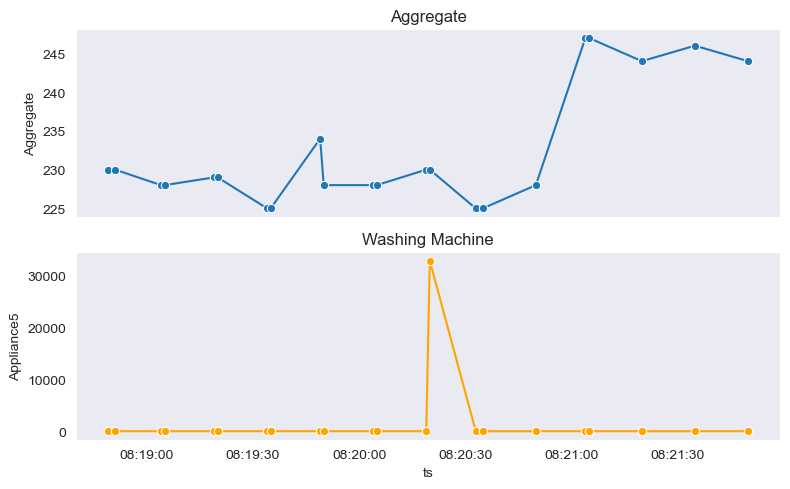

In [21]:
i = df_raw_h1_1["Appliance5"].idxmax()                  # biggest washing machine reading in Part 1
win = df_raw_h1_1.loc[i - 15: i + 15]
print("biggest reading:", df_raw_h1_1.loc[i, "Appliance5"], "W at", df_raw_h1_1.loc[i, "Time"])

fig, axes = plt.subplots(2, 1, sharex=True, figsize=(8, 5))
sns.lineplot(x="ts", y="Aggregate", data=win, marker="o", ax=axes[0])
sns.lineplot(x="ts", y="Appliance5", data=win, marker="o", color="orange", ax=axes[1])
axes[0].set_title("Aggregate")
axes[1].set_title("Washing Machine")
plt.tight_layout()
plt.show()

<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;">The washing machine shows <span style="color:#0A6E68;">one</span> reading of 32,767 W and goes straight back to 0. The aggregate does not move. So it is a glitch, not real power.</div>

<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;"><span style="color:#0A6E68;">Fix later:</span> treat appliance readings above 4,000 W as invalid (set them to <span style="color:#0A6E68;">NaN</span>).</div>

<div style="border-left:5px solid #0FB9B1;background:#E9FBFA;padding:10px 18px;border-radius:0 6px 6px 0;margin:14px 0 8px 0;"><h3 style="color:#12312F;margin:0;font-weight:normal;">4.3 The aggregate above 10 kW</h3></div>

We cannot use a 4,000 W limit for the aggregate, because a whole house can use more. Let's see how often it goes high.

Part1: rows above 10 kW = 10,156, above 15 kW = 82
Part2: rows above 10 kW = 10,941, above 15 kW = 104
Part2 most common Aggregate values above 10 kW: {12505.0: 1534, 10569.0: 49, 24000.0: 38}


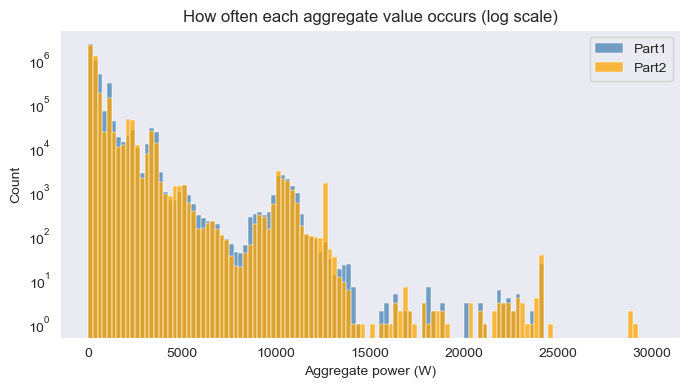

In [22]:
for name, df in PARTS.items():
    print(f"{name}: rows above 10 kW = {int((df['Aggregate'] > 10000).sum()):,}, above 15 kW = {int((df['Aggregate'] > 15000).sum())}")

print("Part2 most common Aggregate values above 10 kW:",
      df_raw_h1_2.loc[df_raw_h1_2["Aggregate"] > 10000, "Aggregate"].value_counts().head(3).to_dict())

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(df_raw_h1_1["Aggregate"], bins=np.arange(0, 30001, 250), color="steelblue", label="Part1", ax=ax)
sns.histplot(df_raw_h1_2["Aggregate"].dropna(), bins=np.arange(0, 30001, 250), color="orange", label="Part2", ax=ax)
ax.set(yscale="log", xlabel="Aggregate power (W)", title="How often each aggregate value occurs (log scale)")
ax.legend()
plt.show()

<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;"><ul style="margin:6px 0 0 0;color:#12312F;"><li style="margin-bottom:4px;">About 10,000 rows in each part are above 10 kW. In the histogram they form a <span style="color:#0A6E68;">second bump around 10–11 kW</span>. These are real, repeated loads (my guess: an electric shower, which is not one of the 9 monitored appliances). So we must <span style="color:#0A6E68;">not</span> cut the aggregate at 4,000 W.</li>
<li style="margin-bottom:4px;">Above 15 kW there are only a few rows, so those are rare.</li>
<li style="margin-bottom:4px;">One value stands out in Part 2: <span style="color:#0A6E68;">12,505 W appears 1,534 times</span>. The same number repeated for hours is a frozen reading (section 6).</li></ul></div>

<div style="background:linear-gradient(90deg,#0A6E68,#0FB9B1);padding:22px 28px;border-radius:10px;margin:18px 0 10px 0;"><h2 style="color:#ffffff;margin:0;font-weight:normal;">5. Do Part 1 and Part 2 overlap?</h2></div>

Part 1 ends 2014-10-01 and Part 2 starts 2014-06-27. If both files record the same house in that period, stacking them would count it twice. I compare their **1-minute averages** in the overlap.

overlap: 2014-06-27 21:57:50 -> 2014-10-01 01:27:07 (95 days)
Aggregate: minutes compared = 119,802, within 5 W of each other = 74%
Washing Machine: minutes compared = 119,802, within 5 W of each other = 98%


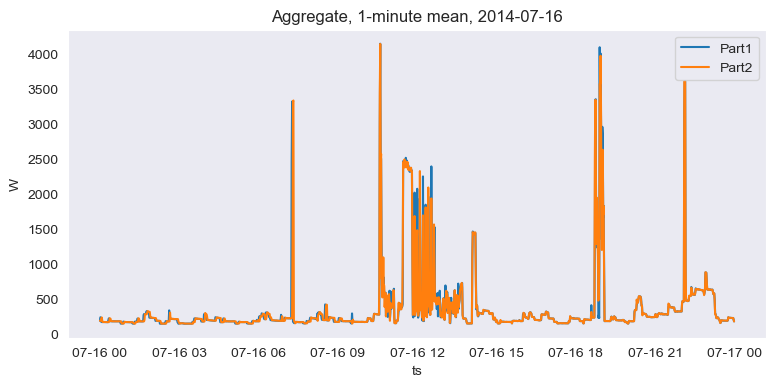

In [23]:
start, end = df_raw_h1_2["ts"].min(), df_raw_h1_1["ts"].max()
print("overlap:", start, "->", end, f"({(end - start).days} days)")

def one_minute(df):
    d = df[(df["ts"] >= start) & (df["ts"] <= end)].drop_duplicates("ts").set_index("ts")
    return d[["Aggregate", "Appliance5"]].resample("1min").mean()

both = one_minute(df_raw_h1_1).join(one_minute(df_raw_h1_2), lsuffix="_p1", rsuffix="_p2").dropna()
for c in ["Aggregate", "Appliance5"]:
    close = ((both[c + "_p1"] - both[c + "_p2"]).abs() <= 5).mean() * 100
    print(f"{H1_NAMES[c]}: minutes compared = {len(both):,}, within 5 W of each other = {close:.0f}%")

day = both.index.normalize().value_counts().idxmax()          # the day with most comparable minutes
sel = both.loc[str(day.date())]
fig, ax = plt.subplots(figsize=(9, 4))
sns.lineplot(x=sel.index, y=sel["Aggregate_p1"], label="Part1", ax=ax)
sns.lineplot(x=sel.index, y=sel["Aggregate_p2"], label="Part2", ax=ax)
ax.set(title=f"Aggregate, 1-minute mean, {day.date()}", ylabel="W")
plt.show()

<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;">The two files record the <span style="color:#0A6E68;">same measurements</span>: the aggregate matches within 5 W in most minutes and the two lines lie on top of each other. So we must <span style="color:#0A6E68;">not stack them</span>. We need to pick one source for each period.</div>

<div style="background:linear-gradient(90deg,#0A6E68,#0FB9B1);padding:22px 28px;border-radius:10px;margin:18px 0 10px 0;"><h2 style="color:#ffffff;margin:0;font-weight:normal;">6. Frozen readings</h2></div>

While plotting a day I saw something odd: for hours the aggregate and the washing machine were **perfectly flat**. Real loads wobble. A flat line this long means the **logger stopped updating and kept repeating the last value**.

I search for stretches of at least 30 minutes where a channel keeps exactly the same non-zero value.

In [24]:
def frozen_runs(df, col, min_minutes=30, min_w=10):
    # stretches where `col` keeps exactly the same value (at least min_w watts) for min_minutes or more
    s = df[["ts", col]].dropna()
    run_id = (s[col] != s[col].shift()).cumsum()              # new id each time the value changes
    g = s.groupby(run_id).agg(value=(col, "first"), start=("ts", "min"), end=("ts", "max"))
    g["minutes"] = (g["end"] - g["start"]).dt.total_seconds() / 60
    return g[(g["minutes"] >= min_minutes) & (g["value"] >= min_w)].sort_values("minutes", ascending=False).reset_index(drop=True)

frozen_agg = frozen_runs(df_raw_h1_2, "Aggregate")
frozen_wm = frozen_runs(df_raw_h1_2, "Appliance5")
print("Part 2: frozen stretches on the Aggregate:", len(frozen_agg), "| on the Washing Machine:", len(frozen_wm))
print("\nlongest ones on the Aggregate")
display(frozen_agg.head(5))
print("on the Washing Machine")
display(frozen_wm)

Part 2: frozen stretches on the Aggregate: 18 | on the Washing Machine: 2

longest ones on the Aggregate


,value,start,end,minutes
0,227.00,2014-08-01 17:12:18,2014-08-02 14:04:05,"1,251.78"
1,496.00,2014-09-06 22:52:04,2014-09-07 13:24:53,872.82
2,167.00,2015-02-18 16:17:38,2015-02-18 21:41:00,323.37
3,183.00,2014-09-07 14:42:05,2014-09-07 18:36:28,234.38
4,"12,505.00",2015-02-08 13:24:00,2015-02-08 16:12:32,168.53


on the Washing Machine


,value,start,end,minutes
0,"2,256.00",2015-02-08 13:24:00,2015-02-08 16:12:32,168.53
1,80.00,2014-07-18 09:50:18,2014-07-18 10:44:59,54.68


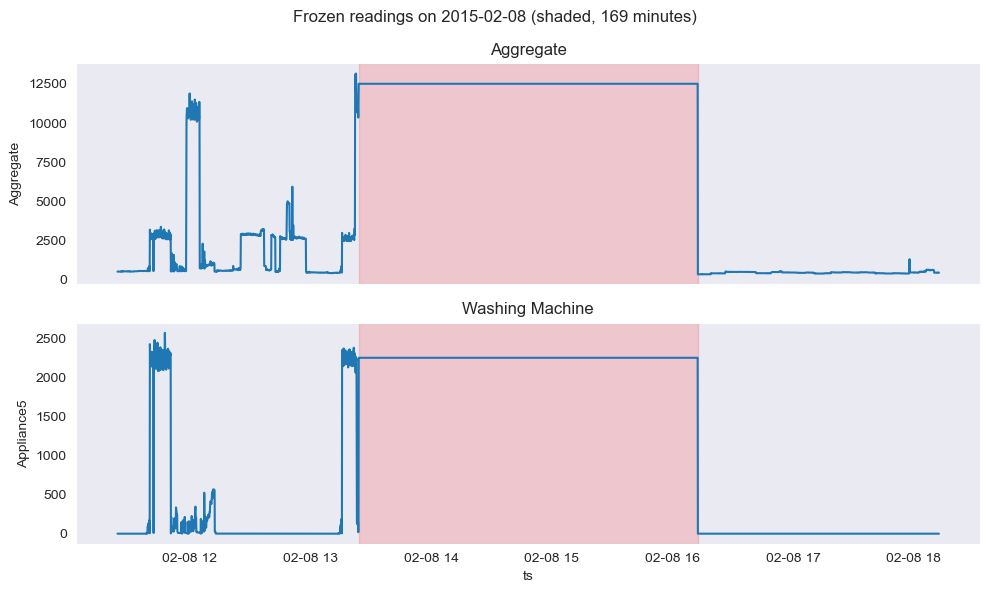

In [25]:
ex = frozen_wm.iloc[0]                                    # the longest frozen washing machine stretch
w = df_raw_h1_2[(df_raw_h1_2["ts"] >= ex["start"] - pd.Timedelta(hours=2)) & (df_raw_h1_2["ts"] <= ex["end"] + pd.Timedelta(hours=2))]

fig, axes = plt.subplots(2, 1, sharex=True, figsize=(10, 6))
for ax, c in zip(axes, ["Aggregate", "Appliance5"]):
    sns.lineplot(x="ts", y=c, data=w, ax=ax)
    ax.axvspan(ex["start"], ex["end"], color="red", alpha=0.15)       # shade the frozen part
    ax.set_title(H1_NAMES[c])
fig.suptitle(f"Frozen readings on {ex['start']:%Y-%m-%d} (shaded, {ex['minutes']:.0f} minutes)")
plt.tight_layout()
plt.show()

<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;">On <span style="color:#0A6E68;">2015-02-08, from 13:24 to 16:12</span>, the aggregate sits at exactly <span style="color:#0A6E68;">12,505 W</span> and the washing machine at exactly <span style="color:#0A6E68;">2,256 W</span>. A washing machine cannot hold one power for almost 3 hours. Both sensors froze at the same moment, so it is the <span style="color:#0A6E68;">logger</span>, not the appliance.</div>

Does this also happen when Part 1 shows a gap? Count the Part 1 rows inside each frozen Part 2 stretch (only for stretches that fall inside Part 1's time range).

In [26]:
part1_end = df_raw_h1_1["ts"].max()
inside = frozen_agg[frozen_agg["end"] <= part1_end].copy()
inside["Part1 rows inside"] = [int(df_raw_h1_1["ts"].between(a, b).sum()) for a, b in zip(inside["start"], inside["end"])]
inside[["value", "start", "end", "minutes", "Part1 rows inside"]]

,value,start,end,minutes,Part1 rows inside
0,227.00,2014-08-01 17:12:18,2014-08-02 14:04:05,"1,251.78",57
1,496.00,2014-09-06 22:52:04,2014-09-07 13:24:53,872.82,4
3,183.00,2014-09-07 14:42:05,2014-09-07 18:36:28,234.38,10
5,279.00,2014-07-21 11:03:11,2014-07-21 13:09:38,126.45,22
8,313.00,2014-07-14 00:41:42,2014-07-14 01:55:31,73.82,19
13,460.00,2014-07-18 09:50:18,2014-07-18 10:44:59,54.68,1
14,245.00,2014-07-11 01:27:14,2014-07-11 02:16:29,49.25,7
17,206.00,2014-09-07 13:52:29,2014-09-07 14:31:09,38.67,4


<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;">Part 1 has almost <span style="color:#0A6E68;">no rows</span> during those frozen stretches. So Part 1 shows a <span style="color:#0A6E68;">gap</span> where Part 2 shows a <span style="color:#0A6E68;">flat line</span>: Part 2 filled the outage with the last value. "No gap" does not mean "no outage".</div>

<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;">The official clean file also keeps these flat stretches (the readme says NaN were forward-filled). <span style="color:#0A6E68;">Fix later:</span> flag stretches of 30+ minutes at one identical value as outages.</div>

<div style="background:linear-gradient(90deg,#0A6E68,#0FB9B1);padding:22px 28px;border-radius:10px;margin:18px 0 10px 0;"><h2 style="color:#ffffff;margin:0;font-weight:normal;">7. What does normal data look like?</h2></div>

A day with a nearly complete record and a washing machine run: **2015-04-20** (Part 2). The appliance panels hide readings above 4,000 W (otherwise one glitch flattens the plot).

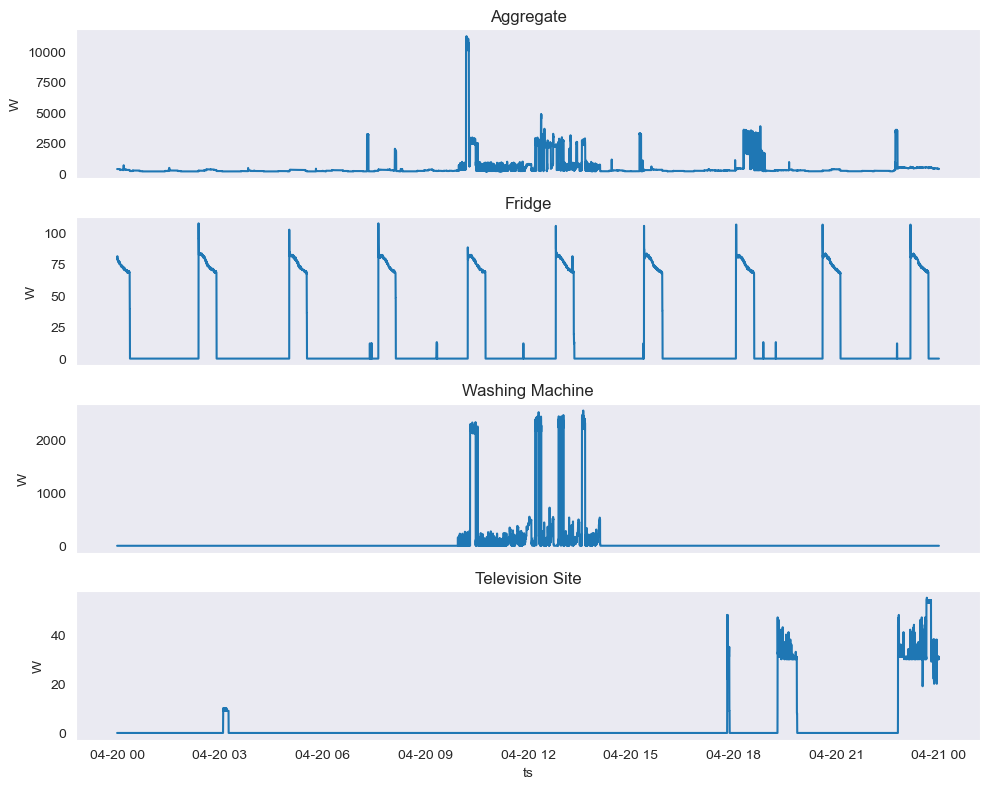

In [27]:
day_df = df_raw_h1_2.set_index("ts").loc["2015-04-20"]
panels = ["Aggregate", "Appliance1", "Appliance5", "Appliance8"]

fig, axes = plt.subplots(len(panels), 1, sharex=True, figsize=(10, 8))
for ax, c in zip(axes, panels):
    s = day_df[c]
    if c != "Aggregate":
        s = s.where(s <= 4000)              # hide the glitches (plot only)
    s = s.dropna()
    sns.lineplot(x=s.index, y=s.values, ax=ax)
    ax.set(title=H1_NAMES[c], ylabel="W")
plt.tight_layout()
plt.show()

<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;"><ul style="margin:6px 0 0 0;color:#12312F;"><li style="margin-bottom:4px;"><span style="color:#0A6E68;">Aggregate:</span> a baseline of about 200–400 W with bursts (one near 11 kW at 10:15).</li>
<li style="margin-bottom:4px;"><span style="color:#0A6E68;">Fridge:</span> a regular on/off cycle, about 80 W when running.</li>
<li style="margin-bottom:4px;"><span style="color:#0A6E68;">Washing Machine:</span> zero until about 10:00, then active until about 14:00, with several high bursts of about 2.3 kW.</li>
<li style="margin-bottom:4px;"><span style="color:#0A6E68;">Television Site:</span> on in the evening at about 30–50 W.</li></ul></div>

<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;">Each appliance has a different power size, and the aggregate is <span style="color:#0A6E68;">everything added together</span>.</div>

Close-up of the washing machine:

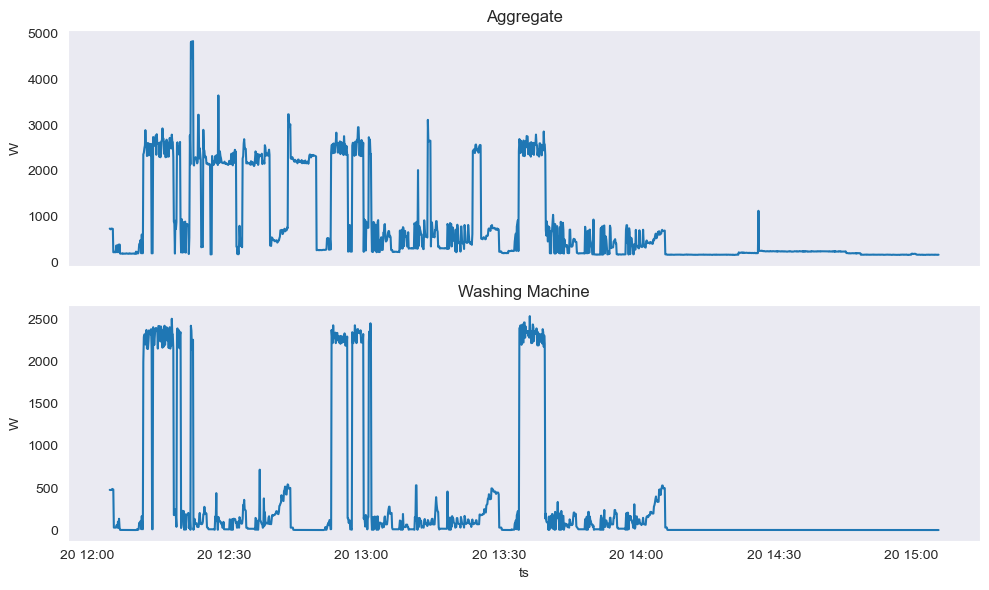

In [28]:
w = day_df.loc["2015-04-20 12:05":"2015-04-20 15:05"]

fig, axes = plt.subplots(2, 1, sharex=True, figsize=(10, 6))
for ax, c in zip(axes, ["Aggregate", "Appliance5"]):
    s = w[c].dropna()
    sns.lineplot(x=s.index, y=s.values, ax=ax)
    ax.set(title=H1_NAMES[c], ylabel="W")
plt.tight_layout()
plt.show()

<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;">The washing machine does <span style="color:#0A6E68;">not</span> use a steady power. It has <span style="color:#0A6E68;">bursts of about 2.3–2.5 kW</span> (my guess: the heater) with low-power stretches in between (my guess: drum motor and pump). The aggregate rises by about the same amount at the same moments, but it also moves for other reasons. Reading the washing machine out of the aggregate is the <span style="color:#0A6E68;">disaggregation problem</span>.</div>

<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;">For the cycle rule later: a cycle must include the low-power parts between bursts, not only the high bursts.</div>

<div style="background:linear-gradient(90deg,#0A6E68,#0FB9B1);padding:22px 28px;border-radius:10px;margin:18px 0 10px 0;"><h2 style="color:#ffffff;margin:0;font-weight:normal;">8. Summary: problems found and what to do</h2></div>

| # | Problem found | Plan for cleaning |
|---|---|---|
| 1 | `Time` is text | convert to datetime |
| 2 | Part 1 not sorted (clock change, jitter) | sort by time |
| 3 | Part 1 has duplicate rows (exact copies and different values at the same timestamp) | drop exact copies, keep the last of the rest |
| 4 | Part 1 and Part 2 overlap for 95 days | use one source per period |
| 5 | Appliance spikes above 4,000 W (sensor glitches) | set to `NaN` before resampling |
| 6 | Aggregate has real readings above 10 kW | do **not** cut the aggregate |
| 7 | Irregular sampling | resample to 1 minute (mean) |
| 8 | Short holes (`NaN`) and real gaps | fill short gaps, **flag** long ones |
| 9 | Frozen readings (logger stopped) | flag stretches of 30+ minutes at one value |
| 10 | Raw clock is UK local time (daylight saving) | keep as is, mention as a limitation |

Next notebook: **02_cleaning**.